<a href="https://colab.research.google.com/github/avi-11-2002/UBER-Assignment/blob/main/Uber_DS_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Insights from City Supply and Demand Data

This data project has been used as a take-home assignment in the recruitment process for the data science positions at Uber.

## Assignment

Using the provided dataset, answer the following questions:

1. Which date had the most completed trips during the two week period?

2. What was the highest number of completed trips within a 24 hour period?

3. Which hour of the day had the most requests during the two week period?

4. What percentages of all zeroes during the two week period occurred on weekend (Friday at 5 pm to Sunday at 3 am)? Tip: The local time value is the start of the hour (e.g. 15 is the hour from 3:00pm - 4:00pm)

5. What is the weighted average ratio of completed trips per driver during the two week period? Tip: "Weighted average" means your answer should account for the total trip volume in each hour to determine the most accurate number in whole period.

6. In drafting a driver schedule in terms of 8 hours shifts, when are the busiest 8 consecutive hours over the two week period in terms of unique requests? A new shift starts in every 8 hours. Assume that a driver will work same shift each day.

7. True or False: Driver supply always increases when demand increases during the two week period. Tip: Visualize the data to confirm your answer if needed.

8. In which 72 hour period is the ratio of Zeroes to Eyeballs the highest?

9. If you could add 5 drivers to any single hour of every day during the two week period, which hour should you add them to? Hint: Consider both rider eyeballs and driver supply when choosing

10. True or False: There is exactly two weeks of data in this analysis

11. Looking at the data from all two weeks, which time might make the most sense to consider a true "end day" instead of midnight? (i.e when are supply and demand at both their natural minimums) Tip: Visualize the data to confirm your answer if needed.


## Data Description
To answer the question, use the dataset from the file dataset_1.csv. For example, consider the row 11 from this dataset:

Date Time (Local) Eyeballs Zeroes Completed Trips Requests Unique Drivers

2012-09-10 16 11 2 3 4 6

This means that during the hour beginning at 4pm (hour 16), on September 10th, 2012, 11 people opened the Uber app (Eyeballs). 2 of them did not see any car (Zeroes) and 4 of them requested a car (Requests). Of the 4 requests, only 3 complete trips actually resulted (Completed Trips). During this time, there were a total of 6 drivers who logged in (Unique Drivers).

## Practicalities

Please work on the questions in the displayed order. Make sure that the solution reflects your entire thought process - it is more important how the code is structured rather than the final answers. You are expected to spend no more than 2-3 hours solving this project.

In [666]:
import pandas as pd
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [667]:
df = pd.read_csv("dataset_1.csv")

In [668]:
df.head()

,Date,Time (Local),Eyeballs,Zeroes,Completed Trips,Requests,Unique Drivers
0,10-Sep-12,7,5,0,2,2,9
1,NaN,8,6,0,2,2,14
2,NaN,9,8,3,0,0,14
3,NaN,10,9,2,0,1,14
4,NaN,11,11,1,4,4,11


In [669]:
df.shape

(336, 7)

In [670]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 336 entries, 0 to 335
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Date              15 non-null     object
 1   Time (Local)      336 non-null    int64 
 2   Eyeballs          336 non-null    int64 
 3   Zeroes            336 non-null    int64 
 4   Completed Trips   336 non-null    int64 
 5   Requests          336 non-null    int64 
 6   Unique Drivers    336 non-null    int64 
dtypes: int64(6), object(1)
memory usage: 18.5+ KB


In [671]:
df.isnull().sum()

,0
Date,321
Time (Local),0
Eyeballs,0
Zeroes,0
Completed Trips,0
Requests,0
Unique Drivers,0


In [672]:
df["Date"].ffill(axis=0, inplace=True)

In [673]:
df.head(15)

,Date,Time (Local),Eyeballs,Zeroes,Completed Trips,Requests,Unique Drivers
0,10-Sep-12,7,5,0,2,2,9
1,10-Sep-12,8,6,0,2,2,14
2,10-Sep-12,9,8,3,0,0,14
3,10-Sep-12,10,9,2,0,1,14
4,10-Sep-12,11,11,1,4,4,11
5,10-Sep-12,12,12,0,2,2,11
6,10-Sep-12,13,9,1,0,0,9
7,10-Sep-12,14,12,1,0,0,9
8,10-Sep-12,15,11,2,1,2,7
9,10-Sep-12,16,11,2,3,4,6


In [674]:
df.isnull().sum()

,0
Date,0
Time (Local),0
Eyeballs,0
Zeroes,0
Completed Trips,0
Requests,0
Unique Drivers,0


In [675]:
df.duplicated().sum()

np.int64(0)

In [676]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 336 entries, 0 to 335
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Date              336 non-null    object
 1   Time (Local)      336 non-null    int64 
 2   Eyeballs          336 non-null    int64 
 3   Zeroes            336 non-null    int64 
 4   Completed Trips   336 non-null    int64 
 5   Requests          336 non-null    int64 
 6   Unique Drivers    336 non-null    int64 
dtypes: int64(6), object(1)
memory usage: 18.5+ KB


In [677]:
df.columns

Index(['Date', 'Time (Local)', 'Eyeballs ', 'Zeroes ', 'Completed Trips ',
       'Requests ', 'Unique Drivers'],
      dtype='object')

Q-1 Which date had the most completed trips during the two week period?

In [678]:
df.head(5)

,Date,Time (Local),Eyeballs,Zeroes,Completed Trips,Requests,Unique Drivers
0,10-Sep-12,7,5,0,2,2,9
1,10-Sep-12,8,6,0,2,2,14
2,10-Sep-12,9,8,3,0,0,14
3,10-Sep-12,10,9,2,0,1,14
4,10-Sep-12,11,11,1,4,4,11


In [679]:
df.groupby("Date").agg(Total_Completed = ("Completed Trips ", "sum")).reset_index().sort_values(by="Total_Completed", ascending=False).head(1)

,Date,Total_Completed
12,22-Sep-12,248


Q-2 What was the highest number of completed trips within a 24 hour period?

In [680]:
df.head(5)

,Date,Time (Local),Eyeballs,Zeroes,Completed Trips,Requests,Unique Drivers
0,10-Sep-12,7,5,0,2,2,9
1,10-Sep-12,8,6,0,2,2,14
2,10-Sep-12,9,8,3,0,0,14
3,10-Sep-12,10,9,2,0,1,14
4,10-Sep-12,11,11,1,4,4,11


In [681]:
df["DateTime"] = pd.to_datetime(
    df["Date"] + " " + df["Time (Local)"].astype(str) + ":00:00"
)

In [682]:
df.head()

,Date,Time (Local),Eyeballs,Zeroes,Completed Trips,Requests,Unique Drivers,DateTime
0,10-Sep-12,7,5,0,2,2,9,2012-09-10 07:00:00
1,10-Sep-12,8,6,0,2,2,14,2012-09-10 08:00:00
2,10-Sep-12,9,8,3,0,0,14,2012-09-10 09:00:00
3,10-Sep-12,10,9,2,0,1,14,2012-09-10 10:00:00
4,10-Sep-12,11,11,1,4,4,11,2012-09-10 11:00:00


In [683]:
df.set_index("DateTime", inplace = True)
df_rolling_sum = df["Completed Trips "].rolling("24H").sum().shift(-23)
df_rolling_sum.sort_values(ascending=False).head(1)

,Completed Trips
DateTime,
2012-09-21 17:00:00,278.0


In [684]:
# df = df.set_index("DateTime").sort_index()
# df_rolling_sum = df["Completed Trips "].rolling("24H").sum().shift(-23)
# df_rolling_sum.head()

In [685]:
df_rolling_sum.sort_values(ascending=False).head(1)

,Completed Trips
DateTime,
2012-09-21 17:00:00,278.0


Q-3 Which hour of the day had the most requests during the two week period?

In [686]:
df.groupby("Time (Local)").agg(Total_Requests = ("Requests ", "sum")).reset_index().sort_values(by="Total_Requests", ascending=False).head(1)

,Time (Local),Total_Requests
23,23,184


Q-4 What percentages of all zeroes during the two week period occurred on weekend (Friday at 5 pm to Sunday at 3 am)?

Tip: The local time value is the start of the hour (e.g. 15 is the hour from 3:00pm - 4:00pm)

In [687]:
df = df.reset_index()
df["Day_of_week"] = df["DateTime"].dt.day_name()
df.head()

,DateTime,Date,Time (Local),Eyeballs,Zeroes,Completed Trips,Requests,Unique Drivers,Day_of_week
0,2012-09-10 07:00:00,10-Sep-12,7,5,0,2,2,9,Monday
1,2012-09-10 08:00:00,10-Sep-12,8,6,0,2,2,14,Monday
2,2012-09-10 09:00:00,10-Sep-12,9,8,3,0,0,14,Monday
3,2012-09-10 10:00:00,10-Sep-12,10,9,2,0,1,14,Monday
4,2012-09-10 11:00:00,10-Sep-12,11,11,1,4,4,11,Monday


In [688]:
num = df[(df["Day_of_week"] == "Friday") & (df["Time (Local)"] >= 17) | (df["Day_of_week"] == "Saturday") | ((df["Day_of_week"] == "Sunday") & (df["Time (Local)"] < 3))]["Zeroes "].sum()
num

np.int64(641)

In [689]:
denom = df["Zeroes "].sum()
denom

np.int64(1429)

In [690]:
ans = round((num/denom)*100 ,2)
ans

np.float64(44.86)

### Q-5 What is the weighted average ratio of completed trips per driver during the two week period?

Tip: "Weighted average" means your answer should account for the total trip volume in each hour to determine the most accurate number in whole period.

In [691]:
df.head()

,DateTime,Date,Time (Local),Eyeballs,Zeroes,Completed Trips,Requests,Unique Drivers,Day_of_week
0,2012-09-10 07:00:00,10-Sep-12,7,5,0,2,2,9,Monday
1,2012-09-10 08:00:00,10-Sep-12,8,6,0,2,2,14,Monday
2,2012-09-10 09:00:00,10-Sep-12,9,8,3,0,0,14,Monday
3,2012-09-10 10:00:00,10-Sep-12,10,9,2,0,1,14,Monday
4,2012-09-10 11:00:00,10-Sep-12,11,11,1,4,4,11,Monday


In [692]:
df_drivers = df[df["Unique Drivers"] > 0]
df_drivers["Ratio"] = df["Completed Trips "] / df["Unique Drivers"]
df_drivers.head()

,DateTime,Date,Time (Local),Eyeballs,Zeroes,Completed Trips,Requests,Unique Drivers,Day_of_week,Ratio
0,2012-09-10 07:00:00,10-Sep-12,7,5,0,2,2,9,Monday,0.222222
1,2012-09-10 08:00:00,10-Sep-12,8,6,0,2,2,14,Monday,0.142857
2,2012-09-10 09:00:00,10-Sep-12,9,8,3,0,0,14,Monday,0.000000
3,2012-09-10 10:00:00,10-Sep-12,10,9,2,0,1,14,Monday,0.000000
4,2012-09-10 11:00:00,10-Sep-12,11,11,1,4,4,11,Monday,0.363636


In [693]:
# Noraml Average
np.average(df_drivers["Ratio"])

np.float64(0.4743397876937869)

In [694]:
num = sum(df_drivers["Ratio"] * df_drivers["Completed Trips "])
denom = sum(df_drivers["Completed Trips "])

# Weighted Average
w_a = round((num / denom * 100), 2)
w_a

82.83

In drafting a driver schedule in terms of 8 hours shifts, when are the busiest 8 consecutive hours over the two week period in terms of unique requests? A new shift starts in every 8 hours. Assume that a driver will work same shift each day.

In [695]:
df.head()

,DateTime,Date,Time (Local),Eyeballs,Zeroes,Completed Trips,Requests,Unique Drivers,Day_of_week
0,2012-09-10 07:00:00,10-Sep-12,7,5,0,2,2,9,Monday
1,2012-09-10 08:00:00,10-Sep-12,8,6,0,2,2,14,Monday
2,2012-09-10 09:00:00,10-Sep-12,9,8,3,0,0,14,Monday
3,2012-09-10 10:00:00,10-Sep-12,10,9,2,0,1,14,Monday
4,2012-09-10 11:00:00,10-Sep-12,11,11,1,4,4,11,Monday


In [696]:
df = df.set_index("DateTime").sort_index()
df_rolling_sum = df["Requests "].rolling("8H").sum().shift(-7)
df_rolling_sum.head()

,Requests
DateTime,
2012-09-10 07:00:00,11.0
2012-09-10 08:00:00,11.0
2012-09-10 09:00:00,13.0
2012-09-10 10:00:00,17.0
2012-09-10 11:00:00,20.0


In [697]:
df_rolling_sum.sort_values(ascending=False).head(2)

,Requests
DateTime,
2012-09-22 19:00:00,207.0
2012-09-21 17:00:00,207.0


 Q-7 True or False: Driver supply always increases when demand increases during the two week period.

 Tip: Visualize the data to confirm your answer if needed.

In [698]:
df = df.reset_index()
df.head()

,DateTime,Date,Time (Local),Eyeballs,Zeroes,Completed Trips,Requests,Unique Drivers,Day_of_week
0,2012-09-10 07:00:00,10-Sep-12,7,5,0,2,2,9,Monday
1,2012-09-10 08:00:00,10-Sep-12,8,6,0,2,2,14,Monday
2,2012-09-10 09:00:00,10-Sep-12,9,8,3,0,0,14,Monday
3,2012-09-10 10:00:00,10-Sep-12,10,9,2,0,1,14,Monday
4,2012-09-10 11:00:00,10-Sep-12,11,11,1,4,4,11,Monday


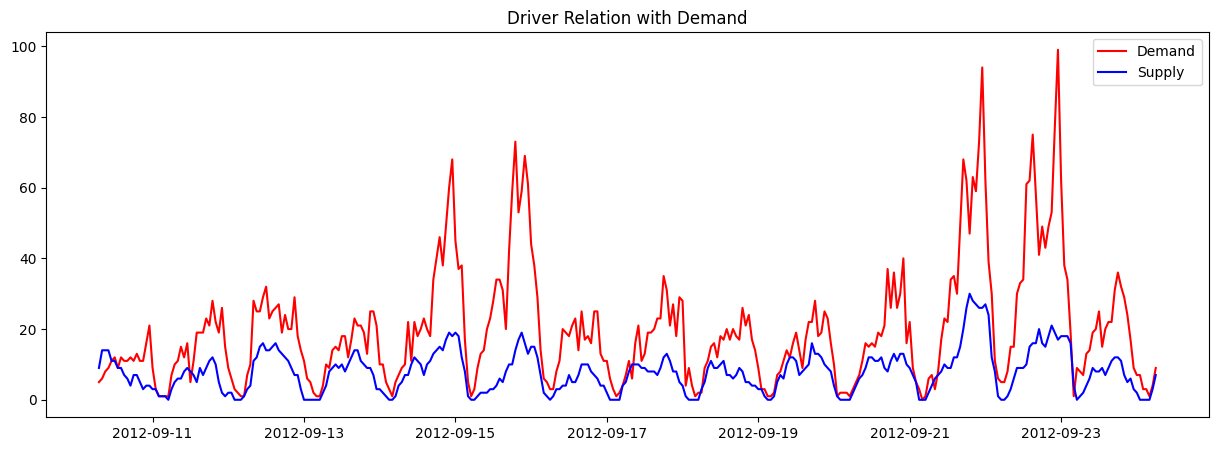

In [699]:
plt.figure(figsize=(15,5))
plt.plot(df["DateTime"], df["Eyeballs "], color="red", label="Demand")
plt.plot(df["DateTime"], df["Unique Drivers"], color="blue", label="Supply")
plt.title("Driver Relation with Demand")
plt.legend()

In [700]:
# Answer is "False"

In which 72 hour period is the ratio of Zeroes to Eyeballs the highest?

In [701]:
# df = df.set_index("DateTime").sort_index()
# df_rolling_sum = df["Zeroes "].rolling("72H").sum().shift(-71) / df["Eyeballs "].rolling("72H").sum().shift(-71)
# df_rolling_sum.sort_values(ascending=False).head(1)

In [702]:
df.set_index("DateTime", inplace=True)
df_rolling_sum = df["Zeroes "].rolling("72H").sum().shift(-71) / df["Eyeballs "].rolling("72H").sum().shift(-71)
df_rolling_sum.sort_values(ascending=False).head(1)

,0
DateTime,
2012-09-15 05:00:00,0.292977
